# Side Effect Detection in Medicine Reviews.

In [3]:
import numpy as np
import pandas as pd
import  matplotlib.pyplot as plt
import seaborn as sns
import re
import string
import pathlib
from pathlib import Path

In [4]:
BASE = Path("..")
# df = pd.read_csv("medice_side_effect_reviews.csv")
DATA_PATH = BASE / "data" / "raw" / "patient_medicine_reviews.csv"
# print("Total reviews:", len(df))
# df.head(20)

In [5]:
# dataset load
df = pd.read_csv(DATA_PATH)
# df=pd.read_csv("patient_medicine_reviews.csv")

## EDA

In [6]:
df.columns

Index(['id', 'gender', 'age', 'medicine', 'condition', 'review', 'label'], dtype='str')

In [7]:
df.shape

(10000, 7)

In [8]:
df.isnull().sum()

id             0
gender       303
age          514
medicine     183
condition    359
review       100
label        100
dtype: int64

In [9]:
df.duplicated().sum()

np.int64(0)

In [10]:
df.dtypes

id             int64
gender           str
age          float64
medicine         str
condition        str
review           str
label            str
dtype: object

In [11]:
df['age']

0       62.0
1       55.0
2       57.0
3        NaN
4       71.0
        ... 
9995    63.0
9996    42.0
9997    59.0
9998    35.0
9999    79.0
Name: age, Length: 10000, dtype: float64

# visualization

<Axes: xlabel='age', ylabel='Count'>

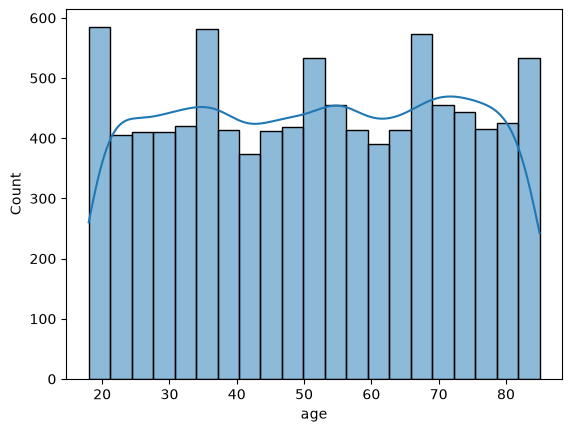

In [12]:
sns.histplot(x=df['age'],kde=True)

<Axes: xlabel='gender', ylabel='count'>

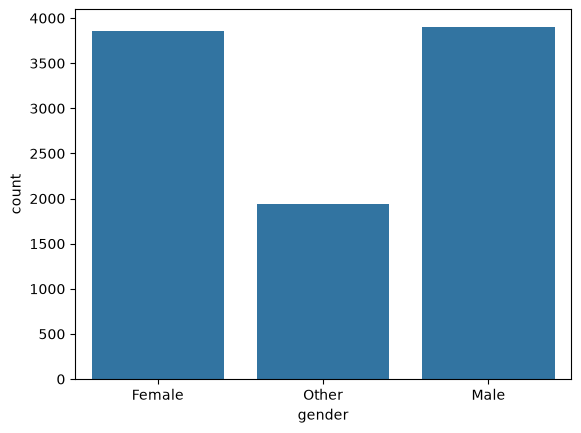

In [13]:
sns.countplot(x=df['gender'])

<Axes: xlabel='label', ylabel='count'>

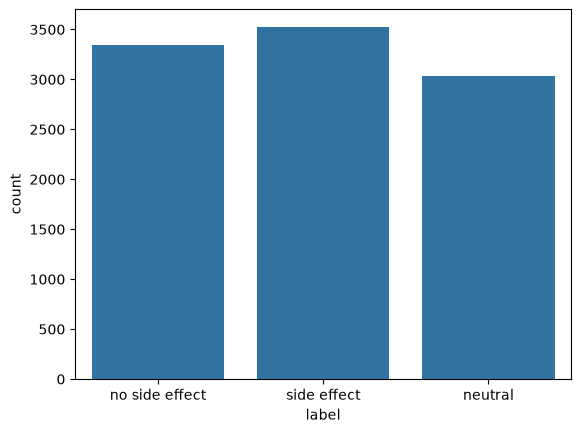

In [14]:
sns.countplot(x=df['label'])

In [15]:


cross_table = pd.crosstab(
    df["gender"],
    df["label"]
)

print(cross_table)

label   neutral  no side effect  side effect
gender                                      
Female     1183            1309         1330
Male       1171            1308         1380
Other       604             622          691


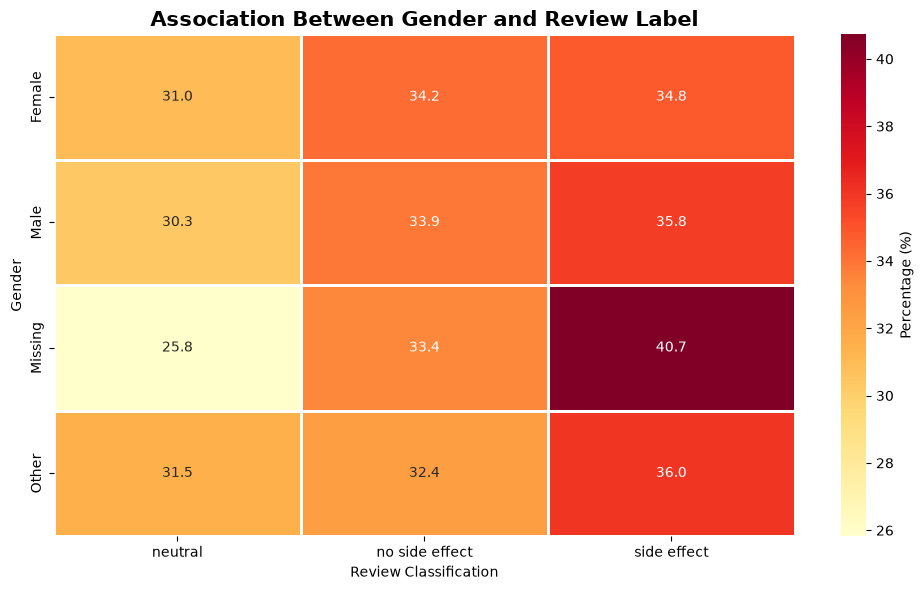

In [16]:
import matplotlib.pyplot as plt
import seaborn as sns

label_map = {
    0: "No Side Effect",
    1: "Side Effect",
    2: "Benefit + Side Effect"
}

data = df[["gender", "label"]].copy()

data["gender"] = (
    data["gender"]
    .fillna("Missing")
    .astype(str)
    .str.strip()
    .str.title()
)

data["label"] = (
    data["label"]
    .map(label_map)
    .fillna(data["label"].astype(str))
)

# Percentage within each gender
percentage_table = pd.crosstab(
    data["gender"],
    data["label"],
    normalize="index"
) * 100

plt.figure(figsize=(10, 6))

sns.heatmap(
    percentage_table,
    annot=True,
    fmt=".1f",
    cmap="YlOrRd",
    linewidths=1,
    linecolor="white",
    cbar_kws={"label": "Percentage (%)"}
)

plt.title(
    "Association Between Gender and Review Label",
    fontsize=15,
    fontweight="bold"
)
plt.xlabel("Review Classification")
plt.ylabel("Gender")
plt.tight_layout()
plt.show()

In [17]:
# sns.boxplot(x=df['label'])



# DATA preprocessing

In [18]:
# Step 1: mask for out-of-range ages
invalid_age = (df["age"] > 88) | (df["age"] < 12)
print(invalid_age.sum())  

# Step 2: set only those to missing
df.loc[invalid_age, "age"] = pd.NA

# Step 3: confirm it worked
print(((df["age"] > 88) | (df["age"] < 12)).sum())   # 0
print(df["age"].isnull().sum())   

0
0
514


In [19]:
df = df.dropna(subset=['age'])

In [20]:
df['age'].isnull().sum()

np.int64(0)

In [21]:
df.duplicated().sum()

np.int64(0)

In [22]:
df['gender'].unique()

<ArrowStringArray>
['Female', 'Other', 'Male', nan]
Length: 4, dtype: str

In [23]:
df=df.dropna(subset=['gender'])

In [24]:
df['gender'].isnull().sum()

np.int64(0)

In [25]:
df.isnull().sum()

id             0
gender         0
age            0
medicine     168
condition    329
review        96
label         96
dtype: int64

In [26]:
df.dropna(inplace=True)

In [27]:
# remove html tags


In [28]:
df["review_no_html"] = df["review"].str.replace(r"<[^>]+>", " ", regex=True)

In [29]:
# emojis

In [30]:
# import re

# emoji_pattern = re.compile(
#     "["
#     "\U0001F300-\U0001F5FF"
#     "\U0001F600-\U0001F64F"
#     "\U0001F680-\U0001F6FF"
#     "\U0001F700-\U0001F77F"
#     "\U0001F780-\U0001F7FF"
#     "\U0001F800-\U0001F8FF"
#     "\U0001F900-\U0001F9FF"
#     "\U0001FA00-\U0001FAFF"
#     "\U00002700-\U000027BF"
#     "]"
# )

# df['has_emoji'] = df['review'].apply(
#     lambda x: bool(emoji_pattern.search(str(x)))
# )

# print(df['has_emoji'].value_counts())

In [31]:
# map emojis

In [32]:
import re

emoji_pattern = re.compile(
    r'[\U0001F300-\U0001FAFF\u2600-\u27BF]'
)

emojis = set()

for text in df['review'].dropna():
    emojis.update(emoji_pattern.findall(text))

print(emojis)

{'💊', '🤮', '😞', '👍', '😡', '😊', '👎'}


In [33]:

emoji_map = {
    "🤮": "vomit",
    "👎": "thumbsdown",
    "😡": "angry",
    "😞": "sad",
    "👍": "thumbsup",
    "💊": "pill",
    "😊": "happy"
}

df["patient_review"] = df["review_no_html"].replace(emoji_map, regex=True)

In [34]:
df.head(10)

,id,gender,age,medicine,condition,review,label,review_no_html,patient_review
0,0,Female,62.0,Gabapentin,Nerve Pain,<br>I filled the Gabapentin prescription for n...,no side effect,I filled the Gabapentin prescription for nerv...,I filled the Gabapentin prescription for nerv...
1,1,Other,55.0,Azithromycin,Bacterial Infection,I was given Azithromycin to treat bacterial in...,side effect,I was given Azithromycin to treat bacterial in...,I was given Azithromycin to treat bacterial in...
2,2,Female,57.0,Sitagliptin,Type 2 Diabetes,Sitagliptin for type 2 diabetes. I expected ac...,no side effect,Sitagliptin for type 2 diabetes. I expected ac...,Sitagliptin for type 2 diabetes. I expected ac...
4,4,Other,71.0,Prednisone,Inflammation,Prednisone for inflammation. I was asked to co...,side effect,Prednisone for inflammation. I was asked to co...,Prednisone for inflammation. I was asked to co...
6,6,Female,62.0,Sertraline,Depression,<br>The treatment I mean throughout this revie...,side effect,The treatment I mean throughout this review i...,The treatment I mean throughout this review i...
7,7,Male,82.0,Omeprazole,GERD,three weeks into treatment with Omeprazole: I ...,neutral,three weeks into treatment with Omeprazole: I ...,three weeks into treatment with Omeprazole: I ...
8,8,Other,71.0,Topiramate,Migraine Prevention,here is my update on topiramate after a fortni...,neutral,here is my update on topiramate after a fortni...,here is my update on topiramate after a fortni...
9,9,Female,62.0,Gabapentin,Nerve Pain,here is my update on gabapentin after six days...,no side effect,here is my update on gabapentin after six days...,here is my update on gabapentin after six days...
10,10,Male,54.0,Levothyroxine,Hypothyroidism,Taking Levothyroxine; the reason is hypothyroi...,no side effect,Taking Levothyroxine; the reason is hypothyroi...,Taking Levothyroxine; the reason is hypothyroi...
11,11,Male,53.0,Cetirizine,Allergic Rhinitis,<p>I filled the Cetirizine prescription for al...,neutral,I filled the Cetirizine prescription for alle...,I filled the Cetirizine prescription for alle...


In [35]:
df['age']=df['age'].astype('int')

In [36]:
df=df.drop(columns=['review','review_no_html'])

In [37]:
df

,id,gender,age,medicine,condition,label,patient_review
0,0,Female,62,Gabapentin,Nerve Pain,no side effect,I filled the Gabapentin prescription for nerv...
1,1,Other,55,Azithromycin,Bacterial Infection,side effect,I was given Azithromycin to treat bacterial in...
2,2,Female,57,Sitagliptin,Type 2 Diabetes,no side effect,Sitagliptin for type 2 diabetes. I expected ac...
4,4,Other,71,Prednisone,Inflammation,side effect,Prednisone for inflammation. I was asked to co...
6,6,Female,62,Sertraline,Depression,side effect,The treatment I mean throughout this review i...
...,...,...,...,...,...,...,...
9995,9995,Other,63,Amlodipine,Hypertension,neutral,"A note about my experience with Amlodipine, no..."
9996,9996,Male,42,Clindamycin,Bacterial Infection,no side effect,Taking Clindamycin; the reason is bacterial in...
9997,9997,Male,59,Gabapentin,Nerve Pain,no side effect,checking in after ten days with gabapentin. th...
9998,9998,Male,35,Cetirizine,Allergic Rhinitis,side effect,"for anyone reading, this is my own account of ..."


In [38]:
# lowercase

In [39]:
df['patient_review']=df['patient_review'].apply(lambda x: x.lower())

In [40]:
# df


In [41]:
# map labels
unique_labels=df['label'].unique()

In [42]:
label_dict={}
i=0
for label in unique_labels:
    label_dict[label]=i
    i+=1

df['label']=df['label'].map(label_dict)

In [43]:
label_dict

{'no side effect': 0, 'side effect': 1, 'neutral': 2}

In [44]:
df['label'].unique()

array([0, 1, 2])

In [45]:
# df.head()

In [46]:
df=df[['id','gender','age','condition','patient_review','label']]

In [47]:
df

,id,gender,age,condition,patient_review,label
0,0,Female,62,Nerve Pain,i filled the gabapentin prescription for nerv...,0
1,1,Other,55,Bacterial Infection,i was given azithromycin to treat bacterial in...,1
2,2,Female,57,Type 2 Diabetes,sitagliptin for type 2 diabetes. i expected ac...,0
4,4,Other,71,Inflammation,prednisone for inflammation. i was asked to co...,1
6,6,Female,62,Depression,the treatment i mean throughout this review i...,1
...,...,...,...,...,...,...
9995,9995,Other,63,Hypertension,"a note about my experience with amlodipine, no...",2
9996,9996,Male,42,Bacterial Infection,taking clindamycin; the reason is bacterial in...,0
9997,9997,Male,59,Nerve Pain,checking in after ten days with gabapentin. th...,0
9998,9998,Male,35,Allergic Rhinitis,"for anyone reading, this is my own account of ...",1


In [48]:
df["patient_review"] = (
    df["patient_review"]
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)

In [49]:
df = df.drop_duplicates(subset=["patient_review"]).copy()

In [50]:
df


,id,gender,age,condition,patient_review,label
0,0,Female,62,Nerve Pain,i filled the gabapentin prescription for nerve...,0
1,1,Other,55,Bacterial Infection,i was given azithromycin to treat bacterial in...,1
2,2,Female,57,Type 2 Diabetes,sitagliptin for type 2 diabetes. i expected ac...,0
4,4,Other,71,Inflammation,prednisone for inflammation. i was asked to co...,1
6,6,Female,62,Depression,the treatment i mean throughout this review is...,1
...,...,...,...,...,...,...
9994,9994,Female,33,Back Pain,thought i would finally write about ibuprofen....,2
9995,9995,Other,63,Hypertension,"a note about my experience with amlodipine, no...",2
9996,9996,Male,42,Bacterial Infection,taking clindamycin; the reason is bacterial in...,0
9998,9998,Male,35,Allergic Rhinitis,"for anyone reading, this is my own account of ...",1


# data split

In [51]:
from sklearn.model_selection import train_test_split

In [52]:
# X = df["patient_review"]
# y = df["label"]

In [53]:
# X_train, X_test, y_train, y_test = train_test_split(
#     X,
#     y,
#     test_size=0.2,
#     random_state=42
# )

In [54]:
# 1. Input data
X = df["patient_review"]
y = df["label"]

# 2. Train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# 3. Create TF-IDF
from sklearn.feature_extraction.text import TfidfVectorizer
tfidf = TfidfVectorizer(
    max_features=3000,
    stop_words=None,
    ngram_range=(1, 2),
    min_df=3,
    max_df=0.9
)

# 4. Pass training data
X_train_tfidf = tfidf.fit_transform(X_train)

# 5. Pass testing data
X_test_tfidf = tfidf.transform(X_test)

In [55]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Create model
lr_model = LogisticRegression(max_iter=1000, random_state=42)

# Train model
lr_model.fit(X_train_tfidf, y_train)

# Make predictions
lr_pred = lr_model.predict(X_test_tfidf)

# Calculate accuracy
lr_accuracy = accuracy_score(y_test, lr_pred)

# Display results
print("===== Logistic Regression =====")
print("\nAccuracy:", lr_accuracy)
print("\nClassification Report:")
print(classification_report(y_test, lr_pred, zero_division=0))
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, lr_pred))

===== Logistic Regression =====

Accuracy: 0.8682811577082102

Classification Report:
              precision    recall  f1-score   support

           0       0.86      0.83      0.84       570
           1       0.85      0.87      0.86       598
           2       0.90      0.91      0.90       525

    accuracy                           0.87      1693
   macro avg       0.87      0.87      0.87      1693
weighted avg       0.87      0.87      0.87      1693


Confusion Matrix:
[[471  74  25]
 [ 48 520  30]
 [ 27  19 479]]


In [56]:
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Create Naive Bayes model
nb_model = MultinomialNB()

# Train the model
nb_model.fit(X_train_tfidf, y_train)

# Make predictions
nb_pred = nb_model.predict(X_test_tfidf)

# Calculate accuracy
nb_accuracy = accuracy_score(y_test, nb_pred)

# Display results
print("===== Naive Bayes =====")

print("\nAccuracy:", nb_accuracy)

print("\nClassification Report:")
print(classification_report(y_test, nb_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, nb_pred))

===== Naive Bayes =====

Accuracy: 0.8511518015357353

Classification Report:
              precision    recall  f1-score   support

           0       0.84      0.83      0.84       570
           1       0.82      0.86      0.84       598
           2       0.90      0.87      0.88       525

    accuracy                           0.85      1693
   macro avg       0.85      0.85      0.85      1693
weighted avg       0.85      0.85      0.85      1693


Confusion Matrix:
[[471  76  23]
 [ 55 514  29]
 [ 32  37 456]]


In [57]:
## SVM

In [58]:
from sklearn.svm import LinearSVC

# Create model
svm_model = LinearSVC(max_iter=5000, random_state=42)

# Train model
svm_model.fit(X_train_tfidf, y_train)

# Make predictions
svm_pred = svm_model.predict(X_test_tfidf)

# Calculate accuracy
svm_accuracy = accuracy_score(y_test, svm_pred)

# Display results
print("===== Linear SVM =====")
print("\nAccuracy:", svm_accuracy)
print("\nClassification Report:")
print(classification_report(y_test, svm_pred, zero_division=0))
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, svm_pred))

===== Linear SVM =====

Accuracy: 0.8919078558771412

Classification Report:
              precision    recall  f1-score   support

           0       0.88      0.85      0.86       570
           1       0.87      0.90      0.88       598
           2       0.94      0.93      0.93       525

    accuracy                           0.89      1693
   macro avg       0.89      0.89      0.89      1693
weighted avg       0.89      0.89      0.89      1693


Confusion Matrix:
[[484  67  19]
 [ 47 536  15]
 [ 20  15 490]]


In [59]:
## Decision Tree

In [60]:

from sklearn.tree import DecisionTreeClassifier

# Create model
dt_model = DecisionTreeClassifier(random_state=42)

# Train model
dt_model.fit(X_train_tfidf, y_train)

# Make predictions
dt_pred = dt_model.predict(X_test_tfidf)

# Calculate accuracy
dt_accuracy = accuracy_score(y_test, dt_pred)

# Display results
print("===== Decision Tree =====")
print("\nAccuracy:", dt_accuracy)
print("\nClassification Report:")
print(classification_report(y_test, dt_pred, zero_division=0))
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, dt_pred))

===== Decision Tree =====

Accuracy: 0.8800945067926758

Classification Report:
              precision    recall  f1-score   support

           0       0.89      0.86      0.87       570
           1       0.86      0.90      0.88       598
           2       0.90      0.88      0.89       525

    accuracy                           0.88      1693
   macro avg       0.88      0.88      0.88      1693
weighted avg       0.88      0.88      0.88      1693


Confusion Matrix:
[[488  54  28]
 [ 36 539  23]
 [ 25  37 463]]


In [61]:
## Random forest

In [62]:
# from sklearn.ensemble import RandomForestClassifier

# # Create model
# rf_model = RandomForestClassifier(
#     n_estimators=100,
#     random_state=42,
#     n_jobs=-1
# )

# # Train model
# rf_model.fit(X_train_tfidf, y_train)

# # Make predictions
# rf_pred = rf_model.predict(X_test_tfidf)

# # Calculate accuracy
# rf_accuracy = accuracy_score(y_test, rf_pred)

# # Display results
# print("===== Random Forest =====")
# print("\nAccuracy:", rf_accuracy)
# print("\nClassification Report:")
# print(classification_report(y_test, rf_pred, zero_division=0))
# print("\nConfusion Matrix:")
# print(confusion_matrix(y_test, rf_pred))

In [63]:
#KNN

In [64]:
from sklearn.neighbors import KNeighborsClassifier

# Create model
knn_model = KNeighborsClassifier(
    n_neighbors=5,
    metric="cosine",
    algorithm="brute",
    n_jobs=-1
)

# Train model
knn_model.fit(X_train_tfidf, y_train)

# Make predictions
knn_pred = knn_model.predict(X_test_tfidf)

# Calculate accuracy
knn_accuracy = accuracy_score(y_test, knn_pred)

# Display results
print("===== KNN =====")
print("\nAccuracy:", knn_accuracy)
print("\nClassification Report:")
print(classification_report(y_test, knn_pred, zero_division=0))
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, knn_pred))

===== KNN =====

Accuracy: 0.8192557590076787

Classification Report:
              precision    recall  f1-score   support

           0       0.77      0.86      0.82       570
           1       0.82      0.79      0.81       598
           2       0.87      0.81      0.84       525

    accuracy                           0.82      1693
   macro avg       0.82      0.82      0.82      1693
weighted avg       0.82      0.82      0.82      1693


Confusion Matrix:
[[492  47  31]
 [ 95 472  31]
 [ 48  54 423]]


In [65]:
import pandas as pd
from sklearn.metrics import f1_score

results = pd.DataFrame({
    "Algorithm": [
        "Naive Bayes",
        "Logistic Regression",
        "Linear SVM",
        "Decision Tree",
        
        "KNN"
    ],
    "Accuracy": [
        nb_accuracy,
        lr_accuracy,
        svm_accuracy,
        dt_accuracy,
        
        knn_accuracy
    ],
    "Macro F1": [
        f1_score(y_test, predictions, average="macro", zero_division=0)
        for predictions in [
            nb_pred, lr_pred, svm_pred,
            dt_pred,  knn_pred
        ]
    ]
})

print(results.sort_values("Macro F1", ascending=False).round(4))

             Algorithm  Accuracy  Macro F1
2           Linear SVM    0.8919    0.8931
3        Decision Tree    0.8801    0.8804
1  Logistic Regression    0.8683    0.8692
0          Naive Bayes    0.8512    0.8524
4                  KNN    0.8193    0.8201


             Algorithm  Accuracy
0           Linear SVM    0.8919
1        Decision Tree    0.8801
2  Logistic Regression    0.8683
3          Naive Bayes    0.8512
4                  KNN    0.8193


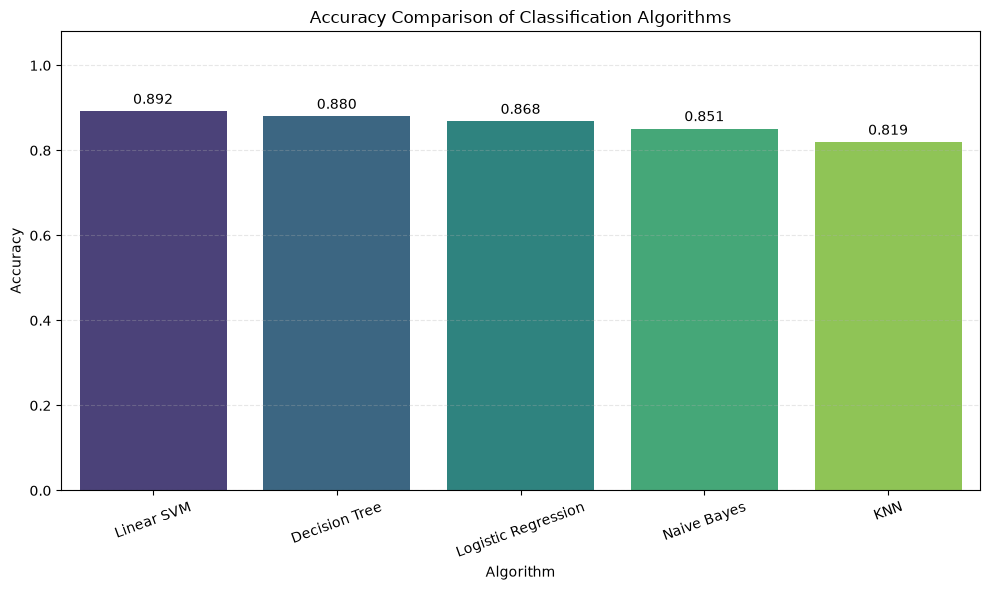

In [66]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# DataFrame
results = pd.DataFrame({
    "Algorithm": [
        "Naive Bayes",
        "Logistic Regression",
        "Linear SVM",
        "Decision Tree",
        "KNN"
    ],
    "Accuracy": [
        nb_accuracy,
        lr_accuracy,
        svm_accuracy,
        dt_accuracy,
        knn_accuracy
    ]
})

#  accuracy
results = results.sort_values(
    "Accuracy",
    ascending=False
).reset_index(drop=True)

print(results.round(4))

#  visualization
plt.figure(figsize=(10, 6))

ax = sns.barplot(
    data=results,
    x="Algorithm",
    y="Accuracy",
    hue="Algorithm",
    palette="viridis",
    legend=False
)


for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.3f",
        padding=3
    )

plt.title("Accuracy Comparison of Classification Algorithms")
plt.xlabel("Algorithm")
plt.ylabel("Accuracy")
plt.ylim(0, 1.08)
plt.xticks(rotation=20)
plt.grid(axis="y", linestyle="--", alpha=0.3)
plt.tight_layout()
plt.show()

In [67]:
new_reviews = [
    "I developed severe stomach pain after taking this medicine",
    "The medicine worked perfectly and I had no problems",
    "I just started taking this medicine and I am not sure if it is working"
]

new_reviews_tfidf = tfidf.transform(new_reviews)

predictions = lr_model.predict(new_reviews_tfidf)

print(predictions)

[1 0 2]


In [68]:
# complex_reviews=["I was initially worried about starting this medication because of everything I had read online, but after several weeks I have not experienced any noticeable side effects and otherwise feel completely normal.",
    
#     "The first couple of days I kept wondering whether the medicine was doing anything, but overall I have tolerated it very well and haven't had any unusual symptoms.",
    
#     "Despite increasing the dose gradually, I have had no problems with nausea, dizziness, headaches, or fatigue, and my daily routine has remained unchanged.",
    
#     "I expected to feel tired after taking this medicine, especially in the morning, but surprisingly I feel exactly the same as before and haven't noticed any negative effects.",
    
#     "I've been taking it consistently for a few weeks and, apart from occasionally forgetting whether I already took my tablet, I haven't noticed anything concerning.",
    
#     "The medication has been easy to tolerate so far. I was concerned about stomach problems, but my appetite and digestion have remained normal.",
    
#     "I experienced some anxiety before starting treatment, but after taking it regularly I haven't developed any physical symptoms that I would associate with the medicine.",
    
#     "So far the treatment has fit into my routine without causing any noticeable discomfort, and I haven't needed to change my normal activities."
# ]
# new_reviews_tfidf = tfidf.transform(new_reviews)

# predictions = model.predict(new_reviews_tfidf)

# print(predictions)

In [69]:
# side_effect_reviews = [
#     "At first I thought the tiredness was probably because I wasn't sleeping well, but after several days I noticed that the fatigue consistently became worse shortly after taking the medication.",
    
#     "I didn't experience anything unusual immediately after the first dose, but by the end of the week I was dealing with persistent nausea and occasional stomach cramps.",
    
#     "The medicine seems to be helping my condition, but unfortunately I have also started experiencing headaches that were not present before treatment.",
    
#     "I initially ignored the dizziness because it was mild, but it has become frequent enough that I now have to sit down whenever I stand up too quickly.",
    
#     "For the first few days everything seemed fine, then I developed a skin rash that became increasingly itchy and uncomfortable.",
    
#     "I can't say whether the medication is completely responsible, but the repeated episodes of nausea and vomiting started shortly after I began taking it.",
    
#     "The treatment has improved some of my symptoms, although I now find myself struggling with insomnia and waking several times during the night.",
    
#     "I was feeling perfectly normal before starting the medicine, but within a week I noticed unusual fatigue, headaches, and occasional dizziness."
# ]
# side_effect_tfidf = tfidf.transform(side_effect_reviews)

# side_effect_predictions = model.predict(side_effect_tfidf)

# print(side_effect_predictions)

In [70]:
# pd.to_csv()

In [71]:
# neutral_reviews = [
#     "I've only been taking the medication for a few days, so I think it is too early to decide whether it is helping or causing any problems.",
    
#     "My doctor prescribed this medicine last week, but I haven't taken it long enough to know how my body will respond.",
    
#     "I recently started the treatment and haven't noticed any major changes yet, although I'm planning to continue monitoring how I feel.",
    
#     "It is difficult to tell whether the medication is working because I have only taken a few doses and my symptoms have not changed significantly.",
    
#     "The prescription was changed recently, so I don't have enough experience with the new medication to say whether it has affected me positively or negatively.",
    
#     "I've been taking the medicine for less than a week and so far I don't have enough information to determine whether the treatment is effective.",
    
#     "My doctor recommended that I give the medication more time before judging the results, so at this point I am still unsure about its effects.",
    
#     "I started this treatment recently and haven't experienced anything clearly different from before, but I think it is too soon to draw any conclusions."
# ]
# neutral_tfidf = tfidf.transform(neutral_reviews)

# neutral_predictions = model.predict(neutral_tfidf)

# print(neutral_predictions)

In [72]:
# df

In [73]:
# neutral_reviews = [
#     "I've only been taking the medication for a few days, so I think it is too early to decide whether it is helping or causing any problems.",
    
#     "My doctor prescribed this medicine last week, but I haven't taken it long enough to know how my body will respond.",
    
#     "I recently started the treatment and haven't noticed any major changes yet, although I'm planning to continue monitoring how I feel.",
    
#     "It is difficult to tell whether the medication is working because I have only taken a few doses and my symptoms have not changed significantly.",
    
#     "The prescription was changed recently, so I don't have enough experience with the new medication to say whether it has affected me positively or negatively.",
    
#     "I've been taking the medicine for less than a week and so far I don't have enough information to determine whether the treatment is effective.",
    
#     "My doctor recommended that I give the medication more time before judging the results, so at this point I am still unsure about its effects.",
    
#     "I started this treatment recently and haven't experienced anything clearly different from before, but I think it is too soon to draw any conclusions."
# ]
# neutral_tfidf = tfidf.transform(neutral_reviews)

# neutral_predictions = nb_model.predict(neutral_tfidf)

# print(neutral_predictions)

# symptom extraction

In [74]:
symptom_list = [
    "fever",
    "headache",
    "nausea",
    "vomiting",
    "dizziness",
    "fatigue",
    "weakness",
    "cough",
    "cold",
    "rash",
    "itching",
    "stomach pain",
    "body pain",
    "chest pain",
    "diarrhea",
    "constipation",
    "insomnia",
    "sore throat",
    "breathing difficulty",
    "loss of appetite"
]

In [75]:
def extract_symptoms(review):

    review = review.lower()

    found_symptoms = []

    for symptom in symptom_list:

        if symptom in review:
            found_symptoms.append(symptom)

    return found_symptoms


# regex symptoms
def regex_extract_symptoms(review):
    review = review.lower()
    found_symptoms = []

    for symptom in symptom_list:
        pattern = r'\b' + re.escape(symptom) + r'\b'
        if re.search(pattern, review):
            found_symptoms.append(symptom)

    return found_symptoms

In [76]:
review = """
The medicine is helping me but I still have
fever, headache and weakness.
"""

symptoms = extract_symptoms(review)

print(symptoms)


symptoms_regex = regex_extract_symptoms(review)
print(symptoms_regex)

['fever', 'headache', 'weakness']
['fever', 'headache', 'weakness']


In [77]:
# medicine extraction'
medicine_list=['Albuterol',
    'Allopurinol',
    'Amlodipine',
    'Amoxicillin',
    'Aspirin',
    'Atorvastatin',
    'Azithromycin',
    'Budesonide',
    'Buspirone',
    'Cetirizine',
    'Clindamycin',
    'Colchicine',
    'Doxycycline',
    'Duloxetine',
    'Empagliflozin',
    'Escitalopram',
    'Fexofenadine',
    'Fluoxetine',]


def extract_medicines(review):

    review = review.lower()

    found_medicines = []

    for medicine in medicine_list:

        if medicine.lower() in review:
            found_medicines.append(medicine)

    return 
review = """
The medicine Azithromycin,Budesonide is helping me but I still have
fever, headache and weakness.
"""

medicine=extract_medicines(review)


# rule based medicine extraction using regex
def regex_extract_medicines(review):
    review = review.lower()
    found_medicines = []

    for medicine in medicine_list:
        pattern = r'\b' + re.escape(medicine.lower()) + r'\b'
        if re.search(pattern, review):
            found_medicines.append(medicine)

    return found_medicines
review = """
The medicine Azithromycin,Budesonide is helping me but I still have"""
print(regex_extract_medicines(review))


['Azithromycin', 'Budesonide']


In [78]:
# df[["patient_review", "extracted_symptoms"]].head(10)


In [79]:
symptoms = extract_symptoms(review)

symptom_text = " ".join(symptoms)

print(symptom_text)

In [80]:
# symptoms = extract_symptoms(review)

# symptom_text = " ".join(symptoms)

# disease = predict_disease(symptom_text)

# print(disease)

In [81]:
# import torch
# from transformers import pipeline

# device = 0 if torch.cuda.is_available() else -1

# medicine_ner = pipeline(
#     "token-classification",
#     model="d4data/biomedical-ner-all",
#     aggregation_strategy="simple",
#     device=device,
# )

# print("Using:", "GPU" if device == 0 else "CPU")

In [82]:
# from transformers import pipeline

# # Load once, then reuse for multiple reviews.
# medicine_ner = pipeline(
#     task="token-classification",
#     model="d4data/biomedical-ner-all",
#     aggregation_strategy="simple",
#     device=-1,  # CPU; use 0 for a compatible CUDA GPU
# )

# def extract_medicines(review):
#     if not isinstance(review, str) or not review.strip():
#         return []

#     entities = medicine_ner(review)
#     medicines = []
#     seen = set()

#     for entity in entities:
#         if entity["entity_group"] == "Medication":
#             # Preserve the original spelling from the review.
#             name = review[entity["start"]:entity["end"]].strip()

#             if name and name.casefold() not in seen:
#                 medicines.append(name)
#                 seen.add(name.casefold())

#     return medicines


# review = "I took Metformin and Ibuprofen yesterday."

# print(extract_medicines(review))

In [83]:
%pip install scispacy==0.5.4
# %pip install https://s3-us-west-2.amazonaws.com/ai2-s2-scispacy/releases/v0.5.4/en_ner_bc5cdr_md-0.5.4.tar.gz

  Using cached scispacy-0.5.4-py3-none-any.whl.metadata (16 kB)
  Using cached spacy-3.7.5.tar.gz (1.3 MB)
  Installing build dependencies: started
  Installing build dependencies: finished with status 'error'
Note: you may need to restart the kernel to use updated packages.


  error: subprocess-exited-with-error
  
  × installing build dependencies for spacy did not run successfully.
  │ exit code: 1
  ╰─> [557 lines of output]
      Ignoring numpy: markers 'python_version < "3.9"' don't match your environment
        Using cached setuptools-84.0.0-py3-none-any.whl.metadata (6.6 kB)
        Using cached Cython-0.29.37-py2.py3-none-any.whl.metadata (3.1 kB)
        Using cached cymem-2.0.13-cp314-cp314-win_amd64.whl.metadata (9.9 kB)
        Using cached preshed-3.0.13-cp314-cp314-win_amd64.whl.metadata (5.4 kB)
        Using cached murmurhash-1.0.15-cp314-cp314-win_amd64.whl.metadata (2.3 kB)
        Using cached thinc-8.2.5.tar.gz (193 kB)
        Installing build dependencies: started
        Installing build dependencies: finished with status 'error'
        error: subprocess-exited-with-error
      
        Ã— installing build dependencies for thinc did not run successfully.
        â”‚ exit code: 1
        â•°â”€> [533 lines of output]
            Ign

In [84]:
#dosage extraction
dosage_list = [
    "mg",
    "ml",
    "g",
    "mcg",
    "iu",
]

def dosage_extraction(review):
    review = review.lower()
    found_dosages = []

    for dosage in dosage_list:
        if dosage in review:
            found_dosages.append(dosage)

    return found_dosages

review="i took 500mg of amoxicillin and 10ml of cough syrup."
dosages = dosage_extraction(review)
print(dosages)

#


['mg', 'ml', 'g']


In [85]:
#regex dosage extraction
def regex_dosage_extraction(review):
    review=review.lower()
    found_dosage=[]
    for dose in dosage_list:
        pattern=r'\b'+ re.escape(dose.lower())+r'\b'
        if re.search(pattern,review):
            found_dosage.append(dose)

        return found_dosage


review="i took 500mg of amoxicillin and 10ml of cough syrup."
dosages = regex_dosage_extraction(review)
print(dosages)
    



[]


In [88]:
#denied symptoms extraction
denied_symptoms_list = [
    "denied",
    "no",
    "none",
    "not",
    "without"
]

def denied_symptoms_extraction(review):
    review = review.lower()
    found_denied_symptoms = []

    for symptom in denied_symptoms_list:
        if symptom in review:
            found_denied_symptoms.append(symptom)

    return found_denied_symptoms

# denied symptom using regex

def regex_denied_symptoms_extraction(review):
    review=review.lower()
    found_denied_symptoms=[]

    for symp in denied_symptoms_list:
            pattern=r'\b'+ re.escape(symp.lower())+r'\b'
            if re.search(pattern,review):
                found_denied_symptoms.append(symp)
    
            return found_denied_symptoms
review="after taking medicine i feel dizziness but no pain"

symptom_denied=denied_symptoms_extraction(review)

print(symptom_denied)


['no']


In [87]:
# Frequency extraction

frequecy_list=["daily","twice","monthly","weekly"]

def frequency_extraction(review):
    review=review.lower()
    frequency_found=[]
    for freq in frequency:
        if freq in review:
            frequency_found.append(freq)
        
    return frequency_found

In [89]:
# regular expressions for entity extraction
import re


narrative="I have been prescribed Albuterol 20 mg for my nausea daily, and I also take Amlodipine for my blood pressure. Additionally, I use Cetirizine for my allergies and have been on Fluoxetine for my pain."
#regex patterns for extracting medications and dosages
medication_pattern = r'\b([A-Z][a-z]+(?:\s[A-Z][a-z]+)*)\b'
dosage_pattern = r'\b(\d+(?:\.\d+)?\s*[a-zA-Z]+)\b'
symptom_pattern = r'\b(nausea|blood pressure|allergies|pain)\b'
medications = re.findall(medication_pattern, narrative)
print("Medications found:", medications)

dosage=re.findall(dosage_pattern, narrative)
print("Dosages found:", dosage)

symptoms = re.findall(symptom_pattern, narrative)
print("Symptoms found:", symptoms)


Medications found: ['Albuterol', 'Amlodipine', 'Additionally', 'Cetirizine', 'Fluoxetine']
Dosages found: ['20 mg']
Symptoms found: ['nausea', 'blood pressure', 'allergies', 'pain']


Extracted entities: {'medications': ['Albuterol', 'Amlodipine', 'Additionally', 'Cetirizine', 'Fluoxetine'], 'dosages': ['20 mg'], 'symptoms': ['nausea', 'blood pressure', 'allergies', 'pain']}


In [91]:
#DENIED  symptoms

# regex patterns for extracting denied symptoms
narrative="I have been prescribed Albuterol 20 mg for my nausea daily, and I also take Amlodipine for my blood pressure. Additionally, I use Cetirizine for my allergies and have been on Fluoxetine for my pain. However, I have denied nausea"
denied_symptom_pattern = r'\b(denied|no|not experiencing)\s(nausea|blood pressure|allergies|pain)\b'
denied_symptoms = re.findall(denied_symptom_pattern, narrative)

print("Denied symptoms found:", denied_symptoms)

Denied symptoms found: [('denied', 'nausea')]


In [92]:

#function to extract medications, dosages, and symptoms from a given narrative using regular expressions
def extract_entities(narrative: str) -> dict[str, list[str]]:  # use type hints for input and output
    # regex patterns for extracting medications, dosages, and symptoms
    medication_pattern = r'\b([A-Z][a-z]+(?:\s[A-Z][a-z]+)*)\b'
    dosage_pattern = r'\b(\d+(?:\.\d+)?\s*[a-zA-Z]+)\b'
    symptom_pattern = r'\b(nausea|blood pressure|allergies|pain)\b'

    # find all matches for medications, dosages, and symptoms
    medications = re.findall(medication_pattern, narrative)
    dosages = re.findall(dosage_pattern, narrative)
    symptoms = re.findall(symptom_pattern, narrative)

    # return the extracted entities as a dictionary
    return {
        "medications": medications,
        "dosages": dosages,
        "symptoms": symptoms
    }

extracted_entities = extract_entities(narrative)
print("Extracted entities:", extracted_entities)

Extracted entities: {'medications': ['Albuterol', 'Amlodipine', 'Additionally', 'Cetirizine', 'Fluoxetine', 'However'], 'dosages': ['20 mg'], 'symptoms': ['nausea', 'blood pressure', 'allergies', 'pain', 'nausea']}
